![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 02 | Build the Core

*Project 3 — AI Product: From Model to Product*

---

Build your solution, compare the design choices with evidence, and choose your final version.

> **Done when:** you have an end-to-end result that beats (or honestly fails to beat) the baseline, and you can say why you chose your final version.

---
## 0. Setup

In [1]:
import os
import logging
import warnings
import re
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(ROOT / ".env")
print("Key found:", "OPENAI_API_KEY" in os.environ)
client = OpenAI()

WINE, FOREST, NAVY, GREY = "#8c2045", "#4f9b63", "#2a5ca8", "#b8b6ae"

Key found: True


---
## 1. LLM track — the pipeline

Build it end to end, with the functions in `src/functions.py`:

- **Retrieval:** embed the chunks, store them (Chroma), retrieve the top `k` with metadata filters.
- **Generation:** a grounded prompt that answers only from the retrieved texts, cites their ids, and says "I don't know" otherwise.
- **Or an agent:** tools with clear descriptions (a retrieval tool, a calculator, web search), a step limit, and a trace you can read.

Run it on three or four questions from your evaluation set and read the answers in full.

In [2]:
chunks = load_chunks()
eval_set = load_eval_set()
answerable = eval_set[eval_set['kind'] != 'out_of_scope']

print(f'{len(chunks)} chunks, {chunks['is_nature'].mean():.0%} from nature articles')
print(f'{len(eval_set)} evaluation questions, {len(answerable)} answerable')

embedding = load_embedder()
print(f'Maximum input: {embedding.max_seq_length} tokens')

11510 chunks, 29% from nature articles
22 evaluation questions, 18 answerable


/Users/jkrstevska/Desktop/DSML/Week 9/project-3-ai-product/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6603.79it/s]


Maximum input: 256 tokens


In [3]:
tokens = [len(embedding.tokenizer(text)['input_ids']) for text in chunks['embed_text']]
print(f'Median tokens per chunk: {int(np.median(tokens))}')
print(f'Share over {embedding.max_seq_length} tokens: {np.mean(np.array(tokens) >  embedding.max_seq_length):.0%}')

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (264 > 256). Running this sequence through the model will result in indexing errors


Median tokens per chunk: 147
Share over 256 tokens: 0%


The median chunk is 196 tokens, so most chunks fit. But 10% of chunks are over 256 tokens, and MiniLM never sees their last part. If the answer to a question is at the end of one of those chunks, retrieval can’t find it. To fix this, I will compare a few chunk sizes and pick the largest one that fits.

In [4]:
articles = load_articles()
rows = []
for size in [100, 105, 115, 120, 150]:
    sample = build_chunks(articles, max_words=size, overlap=size // 5)
    sample_tokens = [len(embedding.tokenizer(text)["input_ids"]) for text in sample["embed_text"]]
    rows.append({"words per chunk": size, "chunks": len(sample),
                 "median tokens": int(np.median(sample_tokens)),
                 "share over 256 tokens": f"{np.mean(np.array(sample_tokens) > embedding.max_seq_length):.0%}"})
pd.DataFrame(rows)

,words per chunk,chunks,median tokens,share over 256 tokens
0,100,11978,140,0%
1,105,11510,147,0%
2,115,10688,158,1%
3,120,10346,164,1%
4,150,8759,196,10%


MiniLM reads at most 256 tokens and Wikivoyage text uses more tokens per word than plain prose (place names with diacritics, prices, the title prefix): at 150 words, 10% of the chunks were over the limit and their ends were never embedded. 105 words is the largest size tested with no chunks over the limit, so the chunks are 105 words with an overlap of 21, giving 11,510 chunks.

In [7]:
# Index the chunks
embeddings = embedding.encode(chunks['embed_text'].tolist(), normalize_embeddings=True, batch_size=64, show_progress_bar=True)
print(embeddings.shape)

collection = make_collection(chunks, embeddings)
print(f'Chunks in the collection {collection.count()}')

Batches: 100%|██████████| 180/180 [00:47<00:00,  3.79it/s]


(11510, 384)
Chunks in the collection 11510


In [8]:
# Retrieve 
question = 'How much is the entry fee for Durmitor National Park?'

In [9]:
print(f'Without filter: {retrieve(question, collection, embedding, k=5, where=None)}')

Without filter:          id                         title                 country  \
0   wv-2832        Durmitor National Park              Montenegro   
1   wv-6501  Plitvice Lakes National Park                 Croatia   
2  wv-10401             Una National Park  Bosnia and Herzegovina   
3   wv-2835        Durmitor National Park              Montenegro   
4   wv-6500  Plitvice Lakes National Park                 Croatia   

            section  distance  \
0  Fees and permits     0.286   
1  Fees and permits     0.447   
2  Fees and permits     0.456   
3               See     0.484   
4  Fees and permits     0.494   

                                                                                                                                                                                                      text  \
0  The entry fee to the park is €5 per day (2025).\n\nIf you enter through a forest path or simply any other entry other than the main gate near Crno Jezero/Black l

In [10]:
print(f'Nature articles only: {retrieve(question, collection, embedding, k=5, where=NATURE_ONLY)}')

Nature articles only:          id                         title                 country  \
0   wv-2832        Durmitor National Park              Montenegro   
1   wv-6501  Plitvice Lakes National Park                 Croatia   
2  wv-10401             Una National Park  Bosnia and Herzegovina   
3   wv-2835        Durmitor National Park              Montenegro   
4   wv-6500  Plitvice Lakes National Park                 Croatia   

            section  distance  \
0  Fees and permits     0.286   
1  Fees and permits     0.447   
2  Fees and permits     0.456   
3               See     0.484   
4  Fees and permits     0.494   

                                                                                                                                                                                                      text  \
0  The entry fee to the park is €5 per day (2025).\n\nIf you enter through a forest path or simply any other entry other than the main gate near Crno Jezero/B

In [11]:
print(SYSTEM)

You answer questions from hikers and nature travellers about the Balkans using ONLY the excerpts provided, which come from Wikivoyage travel guides.
Rules:
- Base every statement on the excerpts. Do not use outside knowledge.
- After each statement, cite the excerpt id(s) in square brackets, e.g. [wv-12].
- If the excerpts do not contain the answer, reply exactly "I don't know based on my guides." and nothing else.
- Answer in 2-4 sentences of plain English.


In [12]:
baseline_answers = pd.read_csv(BASELINE_ANSWERS_FILE).set_index('question_id')['answer']
title_of = dict(zip(chunks['chunk_id'], chunks['title']))

In [13]:
for q in eval_set[eval_set['question_id'].isin(['q01', 'q08', 'q11', 'q16', 'q19'])].itertuples(index=False):
    result = answer(client, q.question, collection, embedding, k=5, where=None)
    print(f"===== {q.question_id}: {q.question}")
    print(f"EXPECTED:  {q.expected_answer}")
    print(f"LLM ALONE: {baseline_answers[q.question_id]}")
    print(f"RAG:       {result['answer']}")
    print(f"Cited:     {[title_of[c] for c in result['cited'] if c in title_of]}")
    print(f"Retrieved: {result['titles']}\n")

===== q01: How much is the entry fee for Durmitor National Park?
EXPECTED:  €5 per day (checked 2025).
LLM ALONE: I don't know. Entry fees for Durmitor National Park can vary depending on the specific area/season (e.g., certain trailheads or zones may differ), so I can’t confirm the current amount.
RAG:       The entry fee for Durmitor National Park is €5 per day (2025). [wv-2832]
Cited:     ['Durmitor National Park']
Retrieved: ['Durmitor National Park', 'Plitvice Lakes National Park', 'Una National Park', 'Durmitor National Park', 'Plitvice Lakes National Park']

===== q08: What are Pelister's Eyes, and can I swim there?
EXPECTED:  Two mountain lakes: the Big lake at 2,218 m and the Small lake at 2,180 m; swimming is possible in the small one in summer; about a 5-hour walk from Dihovo, one way.
LLM ALONE: Pelister’s “Eyes” (often called the “Pelister Eyes”/“Pelisterove oči”) are natural karst springs/rock pools near Mount Pelister in North Macedonia, formed by water emerging from the

RAG answered 4 of the 5 questions correctly and refused the out-of-scope one, citing the right article every time. Where the LLM alone invented details (Pelister’s “karst springs”, a second viewpoint in Tara that is in Bosnia), the RAG answers stayed with the guide and gave the specifics the LLM alone could not (the €5 fee checked in 2025, the lakes’ heights). The question typed without diacritics, “Zabljak”, still retrieved Žabljak first. One answer was incomplete: q16 gave the taxi option but not the bus or the distance. For the snow question, retrieval returned unrelated chunks (Kukës, a near-match for “Kuk”), and the model correctly refused rather than guessing. I checked the Durmitor answer against the Wikivoyage article: it matches the “Fees and permits” section.

---
## 2. LLM track — one design choice, compared

Chunk size, `k`, a metadata filter, the embedding model, the prompt or the tools: change **one** thing and measure it on the evaluation set (at least the retrieval hit rate). Keep the better version, and log the cost of each run.

In [14]:
rows = []
for k in [3, 5]:
    for name, where in [('none', None), ('nature only', NATURE_ONLY)]:
        rate, missed = hit_rate(answerable, collection, embedding, k=k, where=where)
        rows.append({'k': k, 'filter': name, 'hit rate': round(rate, 2), 'missed': missed})

hit_rates = pd.DataFrame(rows)
hit_rates

,k,filter,hit rate,missed
0,3,none,0.83,"[Can I drive to Theth in winter?, Where can I try a via ferrata in Kosovo?, I'd like a long multi-day trek through the Accursed Mountains. What do you suggest?]"
1,3,nature only,0.89,"[Can I drive to Theth in winter?, I'd like a long multi-day trek through the Accursed Mountains. What do you suggest?]"
2,5,none,0.89,"[Can I drive to Theth in winter?, I'd like a long multi-day trek through the Accursed Mountains. What do you suggest?]"
3,5,nature only,0.89,"[Can I drive to Theth in winter?, I'd like a long multi-day trek through the Accursed Mountains. What do you suggest?]"


In [15]:
for question in hit_rates.loc[3, "missed"]:
    display(question, retrieve(question, collection, embedding, k=5)[["id", "title", "section", "distance"]])

'Can I drive to Theth in winter?'

,id,title,section,distance
0,wv-73,Albania,Get around,0.568
1,wv-1631,Bulgaria,Do,0.579
2,wv-167,Prokletije,Get in,0.585
3,wv-7599,Romania,Get around,0.587
4,wv-7598,Romania,Get around,0.589


"I'd like a long multi-day trek through the Accursed Mountains. What do you suggest?"

,id,title,section,distance
0,wv-11442,Žabljak,Do,0.406
1,wv-9691,Targovishte,Do,0.437
2,wv-9690,Targovishte,Do,0.468
3,wv-1272,Breb,Do,0.482
4,wv-3497,Herceg Novi,Do,0.492


The two questions missed at every setting fail for different reasons. For “Can I drive to Theth in winter?”, the general “Get around” chunks of the Albania and Romania country articles outrank the Thethi article and all five distances are high (0.57–0.59). The search matched “driving in winter” rather than Theth. For the Accursed Mountains trek, it retrieved trekking sections from other places (Žabljak, Targovishte, Breb): it matched the kind of request but not the place, because the question uses the English name while the article is titled Prokletije. Neither changes with k or the filter. The second is the riskier one, the retrieved chunks look relevant, so the model may recommend the wrong mountains instead of refusing, which notebook 03 will check.

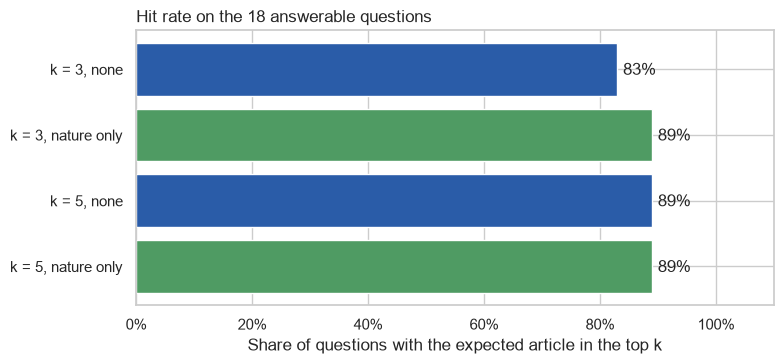

In [38]:
fig, ax = plt.subplots(figsize=(8, 3.8))
labels = [f"k = {r.k}, {r.filter}" for r in hit_rates.itertuples()]
ax.barh(labels, hit_rates["hit rate"], color=[NAVY if f == "none" else FOREST for f in hit_rates["filter"]])
for i, rate in enumerate(hit_rates["hit rate"]):
    ax.annotate(f"{rate:.0%}", (rate, i), textcoords="offset points", xytext=(4, -4))
ax.set_xlim(0, 1.1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title(f"Hit rate on the {len(answerable)} answerable questions", loc="left")
ax.set_xlabel("Share of questions with the expected article in the top k")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

All four settings find the expected article for 15 or 16 of the 18 questions. The only difference is one question, which is within the noise of an 18-question set. 
The final version uses k = 5 with no filter. The filter adds nothing at k = 5 and would make town articles unreachable, so five chunks give the model more context to answer from.

---
## 3. The final version

Which version you will evaluate in notebook 03 and use in the app, and why. Save it: the fitted pipeline with `joblib` (model track), or the index and the configuration (LLM track), in `models/`.

In [39]:
print(f"Final settings: k = {TOP_K}, filter = {WHERE}, embedding model = {EMBEDDING_MODEL}, LLM = {LLM_MODEL}")

saved = open_collection()
print(f'Chunks in the saved collection: {saved.count()}')
retrieve(eval_set['question'].iloc[0], saved, embedding)[['id', 'title', 'section', 'distance']]

Final settings: k = 5, filter = None, embedding model = sentence-transformers/all-MiniLM-L6-v2, LLM = gpt-5.4-nano
Chunks in the saved collection: 11510


,id,title,section,distance
0,wv-2832,Durmitor National Park,Fees and permits,0.286
1,wv-6501,Plitvice Lakes National Park,Fees and permits,0.447
2,wv-10401,Una National Park,Fees and permits,0.456
3,wv-2835,Durmitor National Park,See,0.484
4,wv-6500,Plitvice Lakes National Park,Fees and permits,0.494


In [16]:
DEMO_VISITED = ROOT / 'data' / 'processed' / 'demo_visited.csv'
DEMO_VISITED.unlink(missing_ok=True)

add_visit('Durmitor National Park', 5, chunks, note='loved the lakes and the nature', path=DEMO_VISITED)
add_visit('Thethi', 4, chunks, note='beautiful but hard to reach', path=DEMO_VISITED)
add_visit('Plitvice Lakes National Park', 2, chunks, note='too crowded', path=DEMO_VISITED)
load_visited(DEMO_VISITED)

,title,country,rating,visited_on,note
0,Durmitor National Park,Montenegro,5,,loved the lakes and the nature
1,Thethi,Albania,4,,beautiful but hard to reach
2,Plitvice Lakes National Park,Croatia,2,,too crowded


In [17]:
for place, rating in [("Atlantis", 4), ("Thethi", 7)]:
    try:
        add_visit(place, rating, chunks, path=DEMO_VISITED)
    except ValueError as error:
        print(f"{place}, {rating}: {error}")

Atlantis, 4: 'Atlantis' is not a place in the guides.
Thethi, 7: The rating must be a whole number from 1 to 5.


In [18]:
tools = make_tools(collection, embedding, DEMO_VISITED)
for t in tools:
    print(f'{t.name}: {t.description}\n')

print(tools[1].invoke({}))
print()
print(tools[0].invoke({'query': 'entry fee Durmitor'})[:500])

search_guides: Search the Wikivoyage travel guides for the Balkans (national parks, mountains, hikes, towns, fees, how to get there, where to sleep, safety). Use it for any question about a place.

get_visited_places: List the places the user has already visited, with their rating from 1 (disliked) to 5 (loved) and their note.

- Durmitor National Park (Montenegro): rated 5/5, note: loved the lakes and the nature
- Thethi (Albania): rated 4/5, note: beautiful but hard to reach
- Plitvice Lakes National Park (Croatia): rated 2/5, note: too crowded

[wv-2832] (Durmitor National Park, Montenegro - Fees and permits)
The entry fee to the park is €5 per day (2025).

If you enter through a forest path or simply any other entry other than the main gate near Crno Jezero/Black lake you might possibly not encounter a single ticket check but on weekends there might be rangers around the popular lakes checking and selling tickets.

[wv-2835] (Durmitor National Park, Montenegro - See)
- Most na Tari

In [19]:
print(AGENT_PROMPT)

You are Trail Scout, an assistant for hikers and nature travellers in the Balkans (Albania, Bosnia and Herzegovina, Bulgaria, Croatia, Kosovo, Montenegro, North Macedonia, Romania, Serbia).
Rules:
- Use search_guides for any question about places, parks, hikes, fees, getting there or staying there. Answer only from what it returns, never from your own knowledge.
- Use get_visited_places when the user asks for a recommendation or mentions the places they have been. Do not recommend a place they have already visited and use their ratings to understand what they like.
- After each statement taken from the guides, cite the excerpt id(s) in square brackets, e.g. [wv-12].
- If the guides do not contain the answer, reply exactly "I don't know based on my guides." and nothing else. Live information (weather, current trail or snow conditions) and bookings are never in the guides.
- Answer in at most 5 sentences of plain English.


In [20]:
agent = make_agent(collection, embedding, DEMO_VISITED)

for question in [
    "I loved Durmitor. Which national park should I visit next?",           # needs both tools
    "How much is the entry fee for Durmitor National Park?",                # only the guides
    "Is there snow on the trail to Bobotov Kuk this weekend?",              # out of scope: should refuse
]:
    print("Question:", question)
    show_trace(run_agent(agent, question, step="agent demo"))
    print("\n" + "-" * 80)

Question: I loved Durmitor. Which national park should I visit next?
  -> get_visited_places({})
  -> search_guides({'query': 'national park similar to Durmitor in Balkans lakes nature remote crowd levels'})
  (2,050 input and 155 output tokens)

Answer: Since you loved Durmitor’s lakes and nature, I’d suggest **Skadar Lake National Park (Montenegro)**—it’s described as the largest lake on the Balkans, with very rich flora and fauna and many bird species, plus marked paths for walkers and some cycling routes. [wv-2010] [wv-8633]  
If you want a mountain-and-history alternative with big views, **Lovćen National Park** is another option with notable cultural and historical scenery. [wv-2010]

--------------------------------------------------------------------------------
Question: How much is the entry fee for Durmitor National Park?
  -> search_guides({'query': 'Durmitor National Park entry fee'})
  (1,471 input and 53 output tokens)

Answer: The entry fee for Durmitor National Park is

In [ ]:
# check cited chunks against the answer
for chunk_id in ["wv-2010", "wv-8633"]:
    row = chunks.loc[chunks["chunk_id"] == chunk_id].iloc[0]
    print(f"[{chunk_id}] {row['title']} - {row['section']}\n{row['text']}\n")

[wv-2010] Central Montenegro - Other destinations
- Lovćen National Park – A beautiful mountain with natural, cultural and historical scenery, and the spectacular Mausoleum of Njegoš.
- Skadar Lake National Park – The largest lake on the Balkans and the natural habitat of the very diverse flora and fauna.

[wv-8633] Skadar Lake National Park - Do
(the biggest world colony of approximately 2000 bird pairs); the Whiskered Tern (Chlidonias hybridus); The Great Cormorant (Phalacrocorax carbo); the Ferruginous Duck (Aythya nyroca); the White-tailed Eagle (Haliaeetus albicilla); as well as several hundreds of Grey Heron (Ardea ralloides); There are five ornithological reserves at Skadar Lake: Manastirska tapija, Grmozur, Omerova gorica, Crni zar, Pancevo oko. Hiking This is a good destination for walkers, although not as challenging as Montenegro's North, where the mountains are far higher. The National Park authorities have marked some paths and provided info-boards. Contact the visitor cen

The cited chunks support almost every claim (the largest lake on the Balkans, the birds, the marked paths and cycling routes). Only “big views” for Lovćen is not in the text, a small embellishment. But the agent left out one relevant sentence from the chunk it cited, Skadar Lake is “not as challenging as Montenegro’s North, where the mountains are far higher”. The log says the user loved the hiking in Durmitor, so the guide itself hints that Skadar is gentler than what they liked. The recommendation is grounded, but it matched the lakes and not the hiking. This a generation failure that notebook 03 should look for in the other recommendations.

In [21]:
chat_agent = make_agent(collection, embedding, DEMO_VISITED, memory=True)

for text in ["I'm planning a summer trip to North Macedonia. Which national parks are there for hiking?",
             "How do I get to the first one you recommend?"]:
    run = run_agent(chat_agent, text, thread_id='demo', step='agent memory')
    print(f'User: {text}')
    show_trace(run)
    print()

User: I'm planning a summer trip to North Macedonia. Which national parks are there for hiking?
  -> search_guides({'query': 'North Macedonia national parks hiking'})
  (1,383 input and 156 output tokens)

Answer: North Macedonia has three national parks suitable for hiking: **Pelister National Park**, **Mavrovo National Park**, and **Galičica National Park**. [wv-5704] [wv-11099]  
Pelister is described as popular for its mountain landscapes and Eastern European flora and fauna. [wv-5704]  
Mavrovo is noted for great landscapes year-round and also has attractions like the Sveti Jovan Bigorski Monastery. [wv-5705]  
Galičica National Park is listed among North Macedonia’s “Other destinations” in the guides. [wv-11099]

User: How do I get to the first one you recommend?
  -> search_guides({'query': 'Pelister National Park how to get there'})
  (2,953 input and 193 output tokens)

Answer: Pelister National Park is **14 km from Bitola**, **75 km from Ohrid’s Airport**, or **170 km from Sk

The memory worked. In the second turn, “the first one you recommend” became a search for “Pelister National Park how to get there”, so the agent used its own previous answer from the same thread. The directions are specific and all come from one cited chunk (14 km from Bitola, no public transport, a taxi for about 400 denars). Where the guides had no detail, the agent said so rather than inventing (Galičica is only “listed among Other destinations”). The second turn used about twice the input tokens of the first (2,953 vs 1,383) with only one search, because the whole conversation is sent again on every turn and long chats get more expensive with each message.

In [23]:
log = pd.DataFrame(usage_log)
summary = log.groupby("step", sort=False)[["input", "output"]].sum()
summary["calls"] = log.groupby("step", sort=False).size()
summary["cost ($)"] = [cost(row.input, row.output) for row in summary.itertuples()]
print(f"Total: {len(log)} calls, ${summary['cost ($)'].sum():.4f}")
summary.round(5)

Total: 10 calls, $0.0038


,input,output,calls,cost ($)
step,,,,
answers,3954,263,5,0.00112
agent demo,5147,245,3,0.00134
agent memory,4336,349,2,0.00130


The whole notebook cost $0.0038 for 10 questions. A plain RAG answer cost about $0.0002 (about 790 input tokens). an agent question about twice that, $0.0004–0.0007, because the agent makes several model calls and every tool result, and in a conversation every previous message, is sent back as input. At that rate, 1000 agent questions would cost about 50 cents.